student mental health score prediction

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("Student Social Media And Mental Health Impact.csv")

In [4]:
df.shape

(5000, 13)

In [5]:
df.head(5)

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [6]:
df.isnull().sum()

Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   str    
 2   Country                  5000 non-null   str    
 3   Academic_Level           5000 non-null   str    
 4   Most_Used_Platform       5000 non-null   str    
 5   Purpose_Of_Use           5000 non-null   str    
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   str    
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), str(6)
memory usage: 736.5 KB


In [8]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [14]:
df['Stress_Level'].unique()

<ArrowStringArray>
['Medium', 'Low', 'Very High', 'High']
Length: 4, dtype: str

EDA

<Axes: xlabel='Mental_Health_Score', ylabel='Count'>

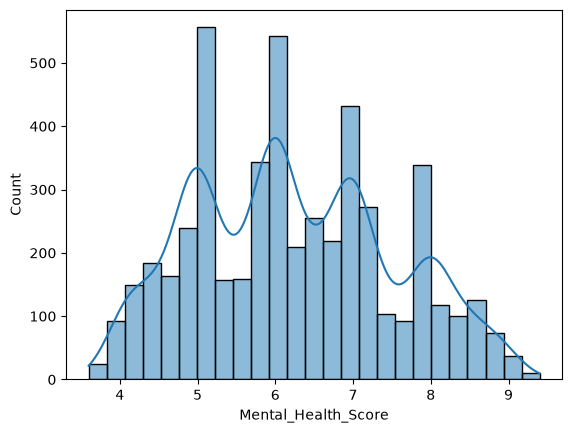

In [11]:
# see the shape of what we are predicting
sns.histplot(df['Mental_Health_Score'],kde = True)

<Axes: >

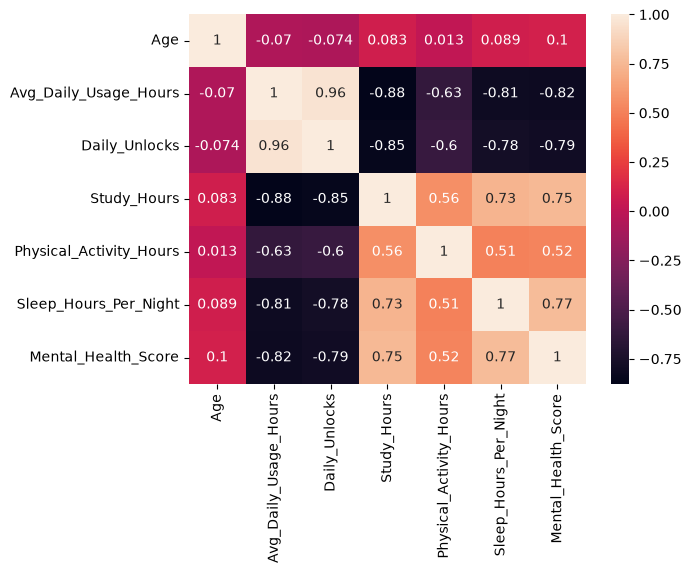

In [12]:
sns.heatmap(df.corr(numeric_only = True),annot = True)

In [13]:
df['Stress_Level'].unique()

<ArrowStringArray>
['Medium', 'Low', 'Very High', 'High']
Length: 4, dtype: str

STRESS LEVEL VS MENTAL HEALTH SCORE

<Axes: xlabel='Stress_Level', ylabel='Mental_Health_Score'>

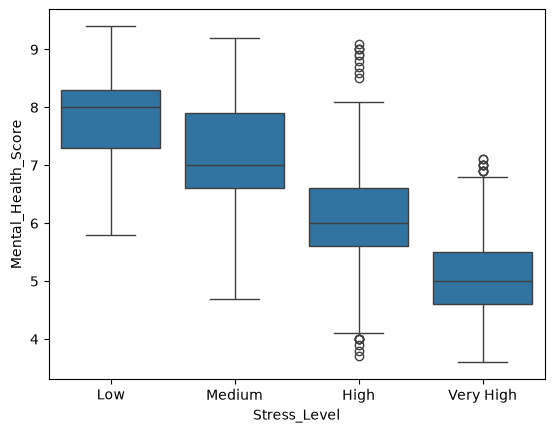

In [14]:
order = ['Low', 'Medium', 'High', 'Very High']
sns.boxplot(x = df['Stress_Level'], y = df['Mental_Health_Score'], order=order)

DAILY USAGE HOURS VS MENTAL HEALTH SCORE

<Axes: xlabel='Avg_Daily_Usage_Hours', ylabel='Mental_Health_Score'>

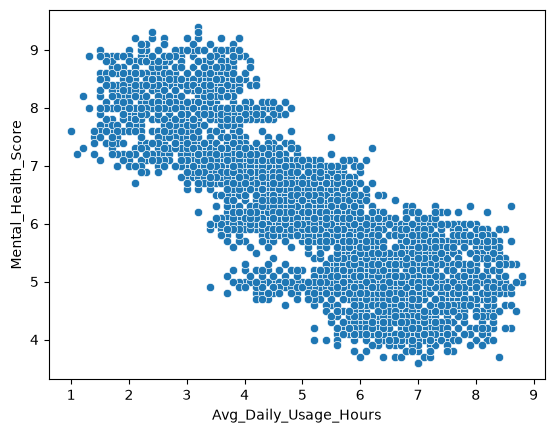

In [15]:
sns.scatterplot(x = df['Avg_Daily_Usage_Hours'], y = df['Mental_Health_Score'])

SLEEP HOURS VS MENTAL HEALTH

<Axes: xlabel='Sleep_Hours_Per_Night', ylabel='Mental_Health_Score'>

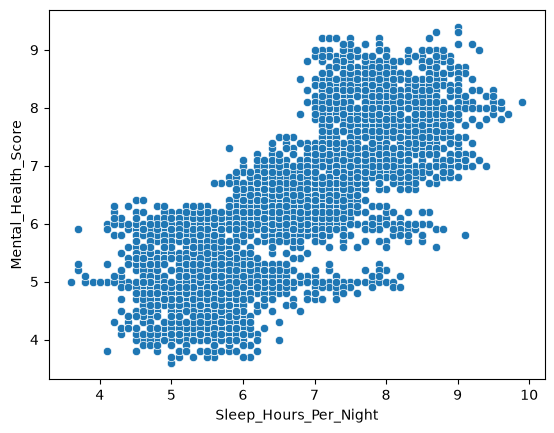

In [16]:
sns.scatterplot(x = df['Sleep_Hours_Per_Night'], y = df['Mental_Health_Score'])

<Axes: xlabel='Physical_Activity_Hours', ylabel='Mental_Health_Score'>

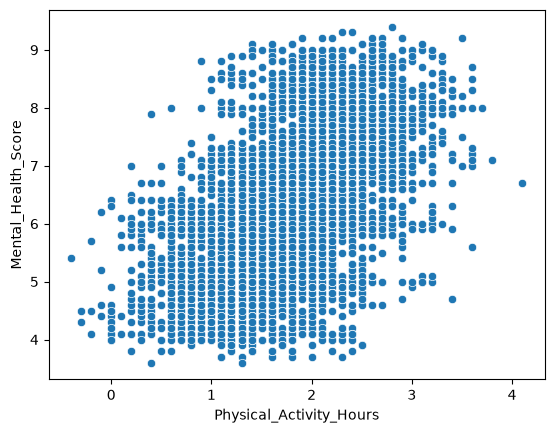

In [17]:
sns.scatterplot(x = df['Physical_Activity_Hours'], y = df['Mental_Health_Score'])

MOST USED PLATFORM

<Axes: xlabel='Most_Used_Platform', ylabel='count'>

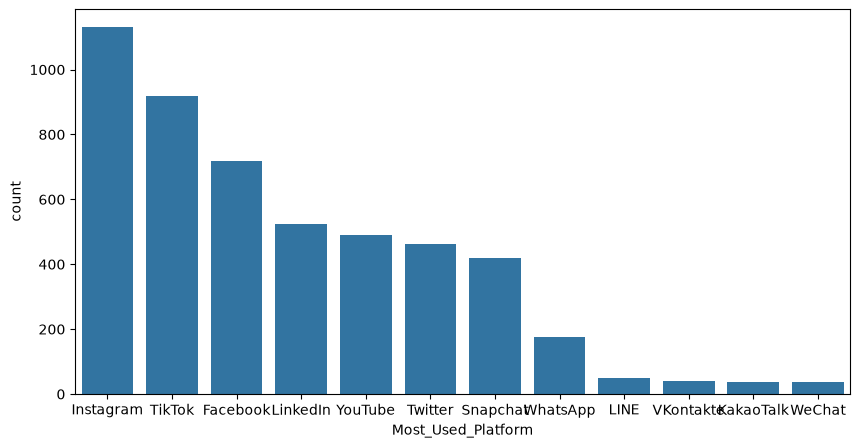

In [18]:
plt.figure(figsize = (10,5))
sns.countplot(x = df['Most_Used_Platform'], order = df['Most_Used_Platform'].value_counts().index)

#**checking outliers**

In [19]:
num_features = df.select_dtypes(include = 'number')
Q1 = num_features.quantile(0.25)
Q3 = num_features.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = (num_features < lower_bound) | (num_features > upper_bound)
outliers.sum()

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64

#DATA CLEANING

In [20]:
df = df.drop_duplicates()

#converting negative values or unrealistic value to realistic value
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower=0)

In [21]:
num_cols = df.select_dtypes(include = 'number')
num_cols.skew()
#most of the data is centralized
# if negative value then left skewed
# if positive value then right skewed
# and to solve the skew problem, we use log transformation

Age                        0.155008
Avg_Daily_Usage_Hours      0.005575
Daily_Unlocks              0.002309
Study_Hours                0.436125
Physical_Activity_Hours    0.053288
Sleep_Hours_Per_Night      0.123919
Mental_Health_Score        0.207086
dtype: float64

# FEATURE ENGINEERING

In [22]:
df.columns


Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='str')

In [23]:
top_countries = df['Country'].value_counts().index[:11].tolist()
top_countries


['Other',
 'India',
 'USA',
 'Canada',
 'Australia',
 'UK',
 'Germany',
 'Mexico',
 'Turkey',
 'France',
 'Spain']

In [24]:
def group_countries(country):
  if country in top_countries:
    return country
  else:
    return 'Other'

In [25]:
df['grouped_countries'] = df['Country'].apply(group_countries)
df['grouped_countries'].value_counts()

grouped_countries
Other        3148
India         389
USA           354
Canada        230
Australia     198
UK            185
Germany       136
Mexico         94
Turkey         94
France         87
Spain          83
Name: count, dtype: int64

<Axes: xlabel='count', ylabel='grouped_countries'>

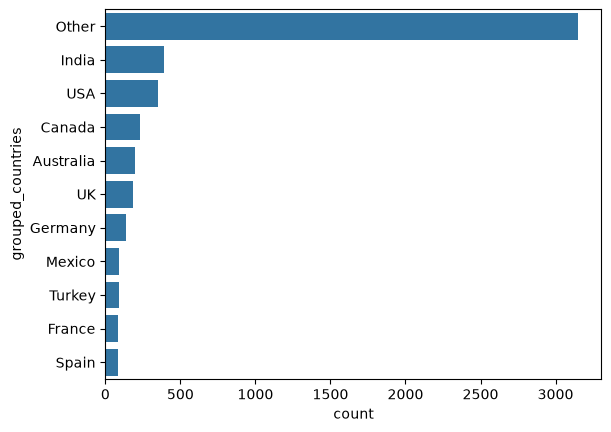

In [26]:
sns.countplot(df['grouped_countries'], order = df['grouped_countries'].value_counts().index)

#STRESS LEVEL -> ORDINAL ENCODING
#GENDER, ACEDAMIC_LEVEL, MOST_USED_PLATFORM, PURPOSE_OF_USE, COUNTRY_GROUPED -> ONEHOT CODING

In [27]:
df.info()

<class 'pandas.DataFrame'>
Index: 4998 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      4998 non-null   int64  
 1   Gender                   4998 non-null   str    
 2   Country                  4998 non-null   str    
 3   Academic_Level           4998 non-null   str    
 4   Most_Used_Platform       4998 non-null   str    
 5   Purpose_Of_Use           4998 non-null   str    
 6   Avg_Daily_Usage_Hours    4998 non-null   float64
 7   Daily_Unlocks            4998 non-null   int64  
 8   Study_Hours              4998 non-null   float64
 9   Physical_Activity_Hours  4998 non-null   float64
 10  Sleep_Hours_Per_Night    4998 non-null   float64
 11  Stress_Level             4998 non-null   str    
 12  Mental_Health_Score      4998 non-null   float64
 13  grouped_countries        4998 non-null   str    
dtypes: float64(5), int64(2), str(7)
memory u

#TRAIN, TEST AND SPLIT

In [28]:
from sklearn.model_selection import train_test_split

skewed_cols = ["Study_Hours"]
other_num_cols = ['Age'	,'Avg_Daily_Usage_Hours',	'Daily_Unlocks',	'Physical_Activity_Hours',
                  'Sleep_Hours_Per_Night']
ordinal_col = ['Stress_Level']
nominal_col = ['Gender' , 'Academic_Level', 'Most_Used_Platform','Purpose_Of_Use','grouped_countries']

feature_cols = skewed_cols + other_num_cols + ordinal_col + nominal_col
x = df[feature_cols]
y = df['Mental_Health_Score']

x_train, x_test, y_train, y_test = train_test_split(x,y,test_size = 0.3, random_state = 42)

#PREPROCESSING USING COLUMN TRANSFORMER

In [29]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer , StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer

skew_pipeline = Pipeline(steps = [
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler())])

plain_numeric_pipeline = Pipeline(steps = [
    ('scale', StandardScaler())
])

ordinal_pipeline = Pipeline(steps = [
    ('encode', OrdinalEncoder(categories = [['Low', 'Medium', 'High', 'Very High']]))
])

nominal_pipeline = Pipeline(steps = [
    ('encode', OneHotEncoder(handle_unknown = 'ignore'))
])

preprocessor = ColumnTransformer(transformers = [
    ('skewed',skew_pipeline, skewed_cols),
    ('plain_numeric', plain_numeric_pipeline, other_num_cols),
    ('ordinal', ordinal_pipeline, ordinal_col),
    ('nominal', nominal_pipeline, nominal_col)
])

#model building

In [30]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

lr_pipeline = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('linear_regressor', LinearRegression())
])

lr_pipeline.fit(x_train, y_train)

lr_predict = lr_pipeline.predict(x_test)
lr_r2_testing = r2_score(y_test, lr_predict)
lr_r2_training = r2_score(y_train, lr_pipeline.predict(x_train))
lr_mae = mean_absolute_error(y_test, lr_predict)
lr_mse = mean_squared_error(y_test, lr_predict)

print('accuracy of trainng: ', lr_r2_training)
print('accuracy of testing: ', lr_r2_testing)
print('mae: ', lr_mae)
print('mse: ', lr_mse)

accuracy of trainng:  0.7284451141767213
accuracy of testing:  0.7431949512902988
mae:  0.5302565031464506
mse:  0.451046510712849


In [31]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps = [
    ('preprocessor' , preprocessor),
    ('random_forest', RandomForestRegressor(random_state = 42))
])
rf_pipeline.fit(x_train, y_train)
predict = rf_pipeline.predict(x_test)
rf_r2_testing = r2_score(y_test, predict)
rf_r2_training = r2_score(y_train, rf_pipeline.predict(x_train))
rf_mae = mean_absolute_error(y_test, predict)
print('r2 score:', r2_score(y_test, predict))
print('r2 score of training:', r2_score(y_train, rf_pipeline.predict(x_train)))
print('mae:', mean_absolute_error(y_test, predict))
print('mse of testing:', mean_squared_error(y_test, predict))
print("mse of training:", mean_squared_error(y_train, rf_pipeline.predict(x_train)))

r2 score: 0.8807141483116341
r2 score of training: 0.9811741220595703
mae: 0.34177136666666685
mse of testing: 0.20951094011500004
mse of training: 0.029758150923384855


#HYPERPARAMETER TUNING

In [32]:
from sklearn.model_selection import RandomizedSearchCV
param_grid = {
    'random_forest__n_estimators': [100, 200, 300],
    'random_forest__max_depth': [5, 10, 15],
    'random_forest__min_samples_split': [2, 5, 10],
    'random_forest__min_samples_leaf': [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator = rf_pipeline,
    param_distributions = param_grid,
    n_iter = 15,
    cv = 5,
    scoring = 'r2',
    random_state = 42,
    n_jobs = -1   #free processor
)

random_search.fit(x_train, y_train)
print('best parameters:', random_search.best_params_)

best parameters: {'random_forest__n_estimators': 300, 'random_forest__min_samples_split': 5, 'random_forest__min_samples_leaf': 2, 'random_forest__max_depth': 15}


In [33]:
rf_best_pipeline = random_search.best_estimator_
rf_best_preds = rf_best_pipeline.predict(x_test)
print(f"R2 Score for random forest after hyperparameter tuning {r2_score(y_test, rf_best_preds)}")
print (f"MAE Score for random forest after hyperparameter tuning {mean_absolute_error(y_test, rf_best_preds)}")

R2 Score for random forest after hyperparameter tuning 0.8658880656691672
MAE Score for random forest after hyperparameter tuning 0.36573207203821667


#MODEL EVALUATION

In [34]:
from sklearn.metrics import mean_squared_error

lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predict))
rf_rmse = np.sqrt(mean_squared_error(y_test, predict))

#calculate rmse for tuned random forest
rf_tuned_preds    = random_search.best_estimator_.predict(x_test)
rf_tuned_rmse     = np.sqrt(mean_squared_error(y_test, rf_tuned_preds))
rf_tuned_training_preds =  random_search.best_estimator_.predict(x_train)
rf_tuned_training = r2_score(y_train, rf_tuned_training_preds)
rf_tuned_mae = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2 = r2_score(y_test, rf_tuned_preds)

results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest', 'Tuned Random Forest'],
    'R2' : [lr_r2_testing, rf_r2_testing, rf_tuned_r2],
    'Training R2' : [lr_r2_training, rf_r2_training, rf_tuned_training],
    'MAE' : [lr_mae, rf_mae, rf_tuned_mae],
    'RMSE' : [lr_rmse, rf_rmse, rf_tuned_rmse]
})

print(results)

results

                 Model        R2  Training R2       MAE      RMSE
0    Linear Regression  0.743195     0.728445  0.530257  0.671600
1        Random Forest  0.880714     0.981174  0.341771  0.457724
2  Tuned Random Forest  0.865888     0.952922  0.365732  0.485336


,Model,R2,Training R2,MAE,RMSE
0,Linear Regression,0.743195,0.728445,0.530257,0.671600
1,Random Forest,0.880714,0.981174,0.341771,0.457724
2,Tuned Random Forest,0.865888,0.952922,0.365732,0.485336


#SAVE THE MODEL

In [35]:
import joblib
joblib.dump(rf_best_pipeline,'Mental_Health_Model.pkl')

['Mental_Health_Model.pkl']